ProteinDataset handles tokenization, padding, and next-token targets.



The vocabulary contains 23 tokens: 20 amino acids, \<PAD>, \<BOS>, and \<EOS>.



Sequences are padded to a maximum length of 129 tokens.


# Step 1: Implement a Transformer

## 1 Load training data with ProteinDataset.

In [16]:
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from protgen.data import ProteinDataset, IGNORE_INDEX

torch.manual_seed(42)

#set device to mps 
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

data_path = Path("../data/train.csv")

train_data = ProteinDataset(data_path)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

print(train_data)
print("Device:", device)


#Understand input data structure
x, x_shifted, y, length = train_data[0]

# Convert token IDs back to amino acid sequences
print("Original protein: ", train_data.decode(x))
print("Protein family:   ", list(train_data.fam_to_idx.keys())[y.item()])
print("Protein length:   ", length)

print("\nInput (x):")
print(x[:15].tolist())

print("\nTarget (x_shifted):")
print(x_shifted[:15].tolist())

print("\nFamily label (y):")
print(y.item())

# Show special tokens and their IDs
print("\nVocabulary:", train_data.vocab)

ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
Device: mps
Original protein:  MIKKQFNIIKNTGFARPATLLVKLSQRFTSDISLEYQGKTINLKHSAKSIMDIMSLSIRPGTKFYIKAEGIDEVQAIQLIQDYLYKEKLINY
Protein family:    HPr
Protein length:    92

Input (x):
[1, 13, 10, 11, 11, 16, 7, 14, 10, 10, 11, 14, 19, 8, 7]

Target (x_shifted):
[13, 10, 11, 11, 16, 7, 14, 10, 10, 11, 14, 19, 8, 7, 3]

Family label (y):
1

Vocabulary: {'<PAD>': 0, '<BOS>': 1, '<EOS>': 2, 'A': 3, 'C': 4, 'D': 5, 'E': 6, 'F': 7, 'G': 8, 'H': 9, 'I': 10, 'K': 11, 'L': 12, 'M': 13, 'N': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'V': 20, 'W': 21, 'Y': 22}


## 2 Transformer that uses masked self-attention to predict next amino acid.

In [ ]:

# Build a Transformer that uses previous amino acids to predict the next one.

class ProteinTransformer(nn.Module):
    def __init__(self, vocab_size, max_length, d_model=128,
                 n_heads=4, n_layers=3, dropout=0.1):
        super().__init__()

        self.max_length = max_length  # Maximum input length (129 tokens for our proteins)

        # Convert each token (A, C, D....) into a trainable vector of 128 numbers
        self.token_embedding = nn.Embedding(vocab_size, d_model)

        # Give each position (0 to 128) its own vector so the model knows token order
        self.position_embedding = nn.Embedding(max_length, d_model)

        # Define one Transformer layer
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,              # Each amino acid is represented by d numbers
            nhead=n_heads,                # 4 attention heads examine different sequence relationships
            dim_feedforward=4 * d_model,  # Expand d features to 4*d, then back to d
            dropout=dropout,              # Randomly drop selected activations during training
            activation="gelu",            # Nonlinear activation in the feed-forward network
            batch_first=True,             # Input format: (proteins, positions, features)
            norm_first=True               # Normalize inputs before attention and feed-forward steps
        )

        # Stack multiple Transformer layers, allowing more complex relationships to be learned
        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=n_layers,
            enable_nested_tensor=False  # Keep standard padded tensors
        )

        # Normalize the final d features at each position
        self.norm = nn.LayerNorm(d_model)


        # Convert d features into vocab_size=23 scores (one for each possible next token)
        self.output = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        # Example input: 32 proteins, each padded to 129 token positions
        B, T = x.shape  # B = number of proteins, T = number of positions

        # Check that the input fits within our position embedding table
        if T > self.max_length:
            raise ValueError("Sequence exceeds max_length")

        # Create position numbers [0, 1, 2, ..., T-1]
        positions = torch.arange(T, device=x.device)

        # Combine which amino acid it is with where it appears in the protein
        # Shape changes from (32, 129) to (32, 129, 128)
        h = self.token_embedding(x) + self.position_embedding(positions)

        # Block attention to future positions: position 3 cannot look at positions 4, 5, ...
        causal_mask = torch.triu(
            torch.ones(T, T, device=x.device, dtype=torch.bool),
            diagonal=1  # Mask positions above the diagonal (future tokens)
        )

        # Process all positions using attention to current and previous tokens only
        h = self.transformer(h, mask=causal_mask)

        # Predict 23 token scores at each position: (32, 129, 23)
        logits = self.output(self.norm(h))

        return logits  # Raw scores; cross-entropy compares these with x_shifted


### Design choices

Causal masking: A position can only attend to itself and previous positions, never future amino acids.



Positional embeddings: Attention alone does not know the ordering of amino acids, so we add learnable position information.



No padding attention mask: Since the repository pads sequences after <EOS> and ignores padded targets during training, causal masking prevents padding from influencing valid predictions.



Output logits: The model returns one vector of 23 scores per position. These are raw scores, not probabilities; CrossEntropyLoss handles the normalization.

# 3 Initialize the model and test a forward pass

In [11]:

model = ProteinTransformer(
    vocab_size=train_data.vocab_size,
    max_length=train_data.max_length,
    d_model=128,
    n_heads=4,
    n_layers=3,
    dropout=0.1
).to(device)

# Take one batch from the existing DataLoader
x, x_shifted, y, lengths = next(iter(train_loader))
x = x.to(device)
x_shifted = x_shifted.to(device)

# Forward pass
logits = model(x)

# Calculate next-token loss, ignoring padded targets
loss = F.cross_entropy(
    logits.reshape(-1, train_data.vocab_size),
    x_shifted.reshape(-1),
    ignore_index=IGNORE_INDEX
)

print("Input shape:", x.shape)
print("Output shape:", logits.shape)
print("Initial loss:", round(loss.item(), 4))
print("Parameters:", sum(p.numel() for p in model.parameters()))


Input shape: torch.Size([32, 129])
Output shape: torch.Size([32, 129, 23])
Initial loss: 3.2386
Parameters: 617495


# Step 2: Train and Tune the Transformer

## 1 Load validation data

In [23]:
val_path = data_path.with_name("val.csv")

val_data = ProteinDataset(val_path)

# Validation data is not shuffled because no training happens on it
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)

# Both datasets must use the same amino acid IDs
assert train_data.vocab == val_data.vocab

print("Training proteins:", len(train_data))
print("Validation proteins:", len(val_data))


Training proteins: 16020
Validation proteins: 2001


## 2. Define one training or validation epoch

Predict the next amino acid using the Transformer.



Compare predictions with x_shifted using cross-entropy loss.



During training, calculate gradients and update the model weights.



Return the average loss per valid target token.

In [24]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)  # Enable dropout for training, disable it for validation

    total_loss = 0.0
    total_tokens = 0

    for x, x_shifted, y, lengths in loader:
        x = x.to(device)
        x_shifted = x_shifted.to(device)

        with torch.set_grad_enabled(training):

            # Predict 23 next-token scores at each position: (B, T, 23)
            logits = model(x)

            # Compare predictions with the actual next amino acid
            loss = F.cross_entropy(
                logits.transpose(1, 2),  # Cross-entropy expects (B, 23, T)
                x_shifted,               # Correct next-token IDs: (B, T)
                ignore_index=IGNORE_INDEX  # Ignore targets after <EOS>
            )

            if training:
                optimizer.zero_grad()  # Clear gradients from the previous batch
                loss.backward()        # Calculate how weights affect the loss

                # Limit large gradients to keep training stable
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

                optimizer.step()       # Update model weights using AdamW

        # Count valid targets so padding does not affect the average
        valid_tokens = (x_shifted != IGNORE_INDEX).sum().item()
        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

    return total_loss / total_tokens


## 3. Define the training loop

In [25]:

import copy
import math

def train_model(model, epochs=12, lr=3e-4, patience=3):

    # AdamW adjusts weights using gradients; weight decay adds regularization
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=0.01
    )

    history = {"train_loss": [], "val_loss": []}
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    for epoch in range(1, epochs + 1):

        # Train on all training proteins, then evaluate on validation proteins
        train_loss = run_epoch(model, train_loader, optimizer)
        val_loss = run_epoch(model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # Perplexity = exp(loss); lower means better predictions
        val_ppl = math.exp(val_loss)

        print(
            f"Epoch {epoch:02d} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f} | "
            f"Val PPL: {val_ppl:.2f}"
        )

        # Save the weights from the best validation epoch
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        # Stop when validation loss has not improved for 'patience' epochs
        if wait >= patience:
            print("Early stopping triggered")
            break

    # Restore weights from the best epoch, not necessarily the last epoch
    model.load_state_dict(best_state)

    return {
        "history": history,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    }


## 4. Train the Transformer

In [34]:

torch.manual_seed(42)

base_config = {
    "d_model": 128,
    "n_heads": 4,
    "n_layers": 3,
    "dropout": 0.1
}

model = ProteinTransformer(
    vocab_size=train_data.vocab_size,
    max_length=train_data.max_length,
    **base_config
).to(device)

# Train and restore the best validation weights
base_result = train_model(
    model,
    epochs=30,
    lr=3e-4,
    patience=3
)

print("\nBest epoch:", base_result["best_epoch"])
print("Best validation loss:", round(base_result["best_val_loss"], 4))


Epoch 01 | Train: 2.3440 | Val: 2.0560 | Val PPL: 7.81
Epoch 02 | Train: 1.9257 | Val: 1.9400 | Val PPL: 6.96
Epoch 03 | Train: 1.7950 | Val: 1.8833 | Val PPL: 6.58
Epoch 04 | Train: 1.7189 | Val: 1.8459 | Val PPL: 6.33
Epoch 05 | Train: 1.6671 | Val: 1.8156 | Val PPL: 6.14
Epoch 06 | Train: 1.6252 | Val: 1.7870 | Val PPL: 5.97
Epoch 07 | Train: 1.5922 | Val: 1.7773 | Val PPL: 5.91
Epoch 08 | Train: 1.5641 | Val: 1.7539 | Val PPL: 5.78
Epoch 09 | Train: 1.5404 | Val: 1.7527 | Val PPL: 5.77
Epoch 10 | Train: 1.5196 | Val: 1.7421 | Val PPL: 5.71
Epoch 11 | Train: 1.5008 | Val: 1.7259 | Val PPL: 5.62
Epoch 12 | Train: 1.4849 | Val: 1.7147 | Val PPL: 5.55
Epoch 13 | Train: 1.4712 | Val: 1.7175 | Val PPL: 5.57
Epoch 14 | Train: 1.4578 | Val: 1.6961 | Val PPL: 5.45
Epoch 15 | Train: 1.4456 | Val: 1.6982 | Val PPL: 5.46
Epoch 16 | Train: 1.4343 | Val: 1.6898 | Val PPL: 5.42
Epoch 17 | Train: 1.4248 | Val: 1.6942 | Val PPL: 5.44
Epoch 18 | Train: 1.4144 | Val: 1.6808 | Val PPL: 5.37
Epoch 19 |

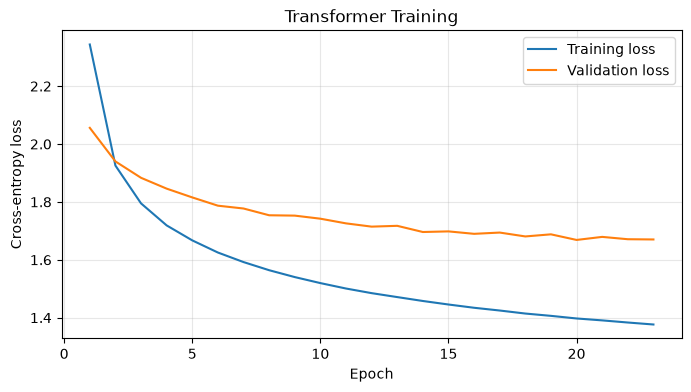

In [35]:
#Plot curve
import matplotlib.pyplot as plt

history = base_result["history"]
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 4))

plt.plot(epochs, history["train_loss"], label="Training loss")
plt.plot(epochs, history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Transformer Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

# Goal: Compare different Transformer configurations using validation loss.

# Keep the already-trained base model as our first experiment
trials = [{
    "name": "Base",
    "config": {**base_config, "lr": 3e-4},
    "result": base_result,
    "model": model
}]

# Move inactive models to CPU to free GPU memory
model.cpu()

# Test a smaller architecture and a lower learning rate
configs = [
    {
        "name": "Smaller",
        "d_model": 64,
        "n_heads": 4,
        "n_layers": 2,
        "dropout": 0.1,
        "lr": 3e-4
    },
    {
        "name": "Lower LR",
        "d_model": 128,
        "n_heads": 4,
        "n_layers": 3,
        "dropout": 0.1,
        "lr": 1e-4
    }
]

for config in configs:
    print(f"\nTraining: {config['name']}")

    torch.manual_seed(42)  # Use the same initialization seed

    trial_model = ProteinTransformer(
        vocab_size=train_data.vocab_size,
        max_length=train_data.max_length,
        d_model=config["d_model"],
        n_heads=config["n_heads"],
        n_layers=config["n_layers"],
        dropout=config["dropout"]
    ).to(device)

    # Train this configuration using the same train/validation split
    result = train_model(
        trial_model,
        epochs=12,
        lr=config["lr"],
        patience=3
    )

    trials.append({
        "name": config["name"],
        "config": config,
        "result": result,
        "model": trial_model
    })

    trial_model.cpu()  # Free GPU memory before the next experiment




Training: Smaller
Epoch 01 | Train: 2.6352 | Val: 2.3293 | Val PPL: 10.27
Epoch 02 | Train: 2.2913 | Val: 2.1413 | Val PPL: 8.51
Epoch 03 | Train: 2.1417 | Val: 2.0738 | Val PPL: 7.95
Epoch 04 | Train: 2.0604 | Val: 2.0346 | Val PPL: 7.65
Epoch 05 | Train: 2.0058 | Val: 2.0121 | Val PPL: 7.48
Epoch 06 | Train: 1.9660 | Val: 1.9916 | Val PPL: 7.33
Epoch 07 | Train: 1.9350 | Val: 1.9706 | Val PPL: 7.17
Epoch 08 | Train: 1.9097 | Val: 1.9554 | Val PPL: 7.07
Epoch 09 | Train: 1.8883 | Val: 1.9431 | Val PPL: 6.98
Epoch 10 | Train: 1.8692 | Val: 1.9292 | Val PPL: 6.88
Epoch 11 | Train: 1.8529 | Val: 1.9194 | Val PPL: 6.82
Epoch 12 | Train: 1.8383 | Val: 1.9134 | Val PPL: 6.78

Training: Lower LR
Epoch 01 | Train: 2.6049 | Val: 2.3096 | Val PPL: 10.07
Epoch 02 | Train: 2.2419 | Val: 2.1119 | Val PPL: 8.26
Epoch 03 | Train: 2.0615 | Val: 2.0237 | Val PPL: 7.57
Epoch 04 | Train: 1.9620 | Val: 1.9745 | Val PPL: 7.20
Epoch 05 | Train: 1.8965 | Val: 1.9358 | Val PPL: 6.93
Epoch 06 | Train: 1.8496


Best configuration: Base
Validation loss: 1.6687
Model  Best epoch  Val loss  Val perplexity
 Base          20    1.6687          5.3052


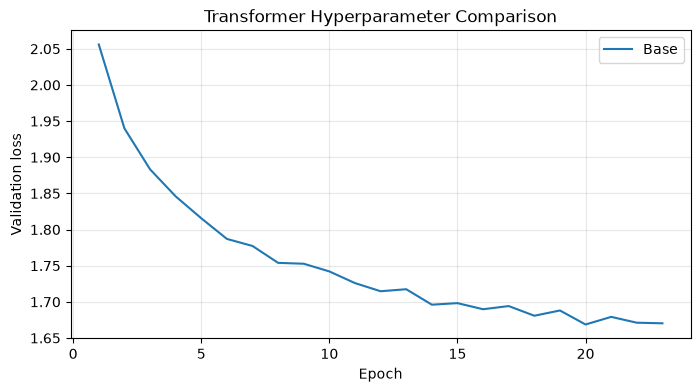


Saved best model to: ../results/models/transformer_best.pt


In [39]:

# Goal: Compare model results and save the best Transformer.

import pandas as pd

# Select the model with the lowest validation loss
best_trial = min(
    trials,
    key=lambda t: t["result"]["best_val_loss"]
)

model = best_trial["model"].to(device)

print("\nBest configuration:", best_trial["name"])
print("Validation loss:", round(best_trial["result"]["best_val_loss"], 4))

# Summarize validation performance across configurations
results_df = pd.DataFrame([
    {
        "Model": t["name"],
        "Best epoch": t["result"]["best_epoch"],
        "Val loss": t["result"]["best_val_loss"],
        "Val perplexity": math.exp(t["result"]["best_val_loss"])
    }
    for t in trials
])

print(results_df.round(4).to_string(index=False))

# Compare validation curves
plt.figure(figsize=(8, 4))

for t in trials:
    losses = t["result"]["history"]["val_loss"]
    plt.plot(range(1, len(losses) + 1), losses, label=t["name"])

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Transformer Hyperparameter Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Save the best model's weights and architecture settings
checkpoint_path = data_path.parent.parent / "results/models/transformer_best.pt"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

best_config = {
    key: best_trial["config"][key]
    for key in ["d_model", "n_heads", "n_layers", "dropout"]
}

torch.save({
    "model_state_dict": model.state_dict(),
    "config": best_config,
    "vocab_size": train_data.vocab_size,
    "max_length": train_data.max_length,
    "val_loss": best_trial["result"]["best_val_loss"]
}, checkpoint_path)

print("\nSaved best model to:", checkpoint_path)


# Step 4: Generate Protein Sequences

## 1. Prepare the trained model

In [40]:

from protgen.data import AA

# Use the model trained to the best validation epoch
generator_model = model  # Change to base_model if that holds your 23-epoch run

generator_model = generator_model.to(device)
generator_model.eval()  # Disable dropout during generation

# Get IDs for special tokens
BOS_ID = train_data.vocab["<BOS>"]
EOS_ID = train_data.vocab["<EOS>"]
PAD_ID = train_data.vocab["<PAD>"]

print("Model device:", next(generator_model.parameters()).device)
print("Vocabulary size:", train_data.vocab_size)


Model device: mps:0
Vocabulary size: 23


## 2. Implement protein generation

In [41]:

@torch.inference_mode()  # Disable gradients to save memory and computation
def generate_proteins(model, n_sequences=20, temperature=1.0,
                      min_length=68, max_length=127):

    if temperature <= 0:
        raise ValueError("Temperature must be positive")

    if not (0 <= min_length <= max_length <= model.max_length - 2):
        raise ValueError("Invalid protein length limits")

    model.eval()
    model_device = next(model.parameters()).device

    # Start every protein with <BOS>, shape: (n_sequences, 1)
    tokens = torch.full(
        (n_sequences, 1), BOS_ID,
        dtype=torch.long, device=model_device
    )

    # Track which proteins have already generated <EOS>
    finished = torch.zeros(n_sequences, dtype=torch.bool, device=model_device)

    for step in range(max_length):

        # Predict next-token scores using all tokens generated so far
        logits = model(tokens)[:, -1, :]  # Shape: (n_sequences, 23)

        # Temperature controls how random the predictions are
        logits = logits / temperature

        # Never generate padding or another beginning-of-sequence token
        logits[:, PAD_ID] = float("-inf")
        logits[:, BOS_ID] = float("-inf")

        # Do not allow sequences to end before 68 amino acids
        if step < min_length:
            logits[:, EOS_ID] = float("-inf")

        # Convert scores into probabilities and sample one token per protein
        probs = torch.softmax(logits, dim=-1)
        next_tokens = torch.multinomial(probs, num_samples=1).squeeze(1)

        # Add padding instead of more amino acids to finished proteins
        next_tokens[finished] = PAD_ID

        # Append new tokens, increasing sequence length by 1
        tokens = torch.cat([tokens, next_tokens.unsqueeze(1)], dim=1)

        # Mark proteins that generated <EOS> as finished
        finished |= (next_tokens == EOS_ID)

        if finished.all():
            break

    # End remaining proteins at the maximum length
    if not finished.all():
        end_tokens = torch.full_like(tokens[:, :1], EOS_ID)
        end_tokens[finished] = PAD_ID
        tokens = torch.cat([tokens, end_tokens], dim=1)

    # Convert token IDs back into amino acid strings
    sequences = [train_data.decode(row) for row in tokens.cpu()]

    return sequences


## Generate and inspect proteins

In [42]:

# Goal: Generate 100 new protein sequences and inspect the results.

torch.manual_seed(42)

generated_sequences = generate_proteins(
    model=generator_model,
    n_sequences=100,
    temperature=1.0,
    min_length=68,
    max_length=127
)

# Display the first five generated proteins
for i, sequence in enumerate(generated_sequences[:5], start=1):
    print(f"Protein {i} ({len(sequence)} amino acids):")
    print(sequence)
    print()

# Check that every sequence contains valid amino acids and lengths
assert all(set(seq).issubset(set(AA)) for seq in generated_sequences)
assert all(68 <= len(seq) <= 127 for seq in generated_sequences)

print("Total generated:", len(generated_sequences))
print("Unique sequences:", len(set(generated_sequences)))
print("Mean length:", sum(map(len, generated_sequences)) / len(generated_sequences))


Protein 1 (91 amino acids):
MSDRDLVYAFSTRVQGVGFRAWTSRSARALGLTAHVRNHAGGTVEVEVQGLGQGVEALVGWCHEGPRTTHVELRVHERDDWQGDHTGFEVR

Protein 2 (99 amino acids):
MNKHELVDKLSEEHARPAPDVPSVDAGLPQPITKEVEAGKTFSLPSMIPLTALRAKTAAPGQTSTILSGITVTGERLAALTKARVVLSKSALNAEHESG

Protein 3 (91 amino acids):
MNKNELIDAVAAKTGQTKVASAETIDAVFAAIGEALSAGDTVQLVGFGSFGVKNYAARTGRNPATGAEINIAASKVPAFTAGKGLKDKVEA

Protein 4 (93 amino acids):
MAERRVNVGWAEGLHARPASIFVRAATAAGVPVTIAKADGAPVNAASMLAVLGLGAQGGEEIVLASDAEGADVALDRLAKLVAEGLEELPETV

Protein 5 (90 amino acids):
MHLISKFLIDGRVQGVGFRKYVKEKANILGLAGFIRTGCDGPVTIVAFGDQDQLKEARSSIKQGPFRAKVTKITERELEITSDEYSFEII

Total generated: 100
Unique sequences: 100
Mean length: 94.58


## Experiment with sampling temperature 

In [43]:

# Goal: Generate proteins using three sampling temperatures.

temperatures = [0.7, 1.0, 1.3]
samples = []

for temp in temperatures:

    sequences = generate_proteins(
        model=generator_model,
        n_sequences=100,
        temperature=temp
    )

    for sequence in sequences:
        samples.append({
            "sequence": sequence,
            "setting": f"temp_{temp}"
        })

    print(
        f"Temperature {temp}: "
        f"{len(set(sequences))}/100 unique proteins"
    )

# Store all generated proteins in a DataFrame
samples_df = pd.DataFrame(samples)

print("\nTotal sequences:", len(samples_df))
samples_df.head()


Temperature 0.7: 100/100 unique proteins
Temperature 1.0: 100/100 unique proteins
Temperature 1.3: 100/100 unique proteins

Total sequences: 300


,sequence,setting
0,MATKKATASTKVLAEIDDAQTVIDAATGLAVLNGELGALEVAEAEA...,temp_0.7
1,MNKGELINNIAEKSGLTKAQAEKVVDAFIEAVAGALKGGDKVALVG...,temp_0.7
2,MTKADIDLKISAKTGIEKADVEKAVESFMGVVKKTLESGDKVSLRG...,temp_0.7
3,MNKTELIDAIAAKSGLTKTDAKKALESFLGNVEGALKKGDKVQLVG...,temp_0.7
4,MALTKAEMAEHLFEKVGLNKREAKDMVEAFFEEIRTCLESGEQVKL...,temp_0.7


## Save generated sequences as CSV

In [ ]:

# Goal: Save generated protein sequences for later evaluation.

# Save under the repository's results/sequences directory
output_path = data_path.parent.parent / "results/sequences/transformer_samples.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

samples_df.to_csv(output_path, index=False)

print("Saved", len(samples_df), "protein sequences")
print("File:", output_path)


In [44]:

# Goal: Check whether generated sequences exactly match training proteins.

training_sequences = set(train_data.df["sequence"])
generated = samples_df["sequence"].tolist()

# Count sequences that already exist in the training set
copied = sum(seq in training_sequences for seq in generated)

print("Generated proteins:", len(generated))
print("Unique proteins:", len(set(generated)))
print("Exact training copies:", copied)
print("Exact copy fraction:", round(copied / len(generated), 4))


Generated proteins: 300
Unique proteins: 300
Exact training copies: 3
Exact copy fraction: 0.01
